In [124]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns

In [125]:
df = pd.read_csv("/kaggle/input/datasets/uciml/iris/Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [126]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Species"].value_counts())

Dataset Shape: (150, 6)

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Class Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [127]:
X = df.drop(columns=["Id", "Species"], errors="ignore")

y = df["Species"]

encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("Classes:", encoder.classes_)

Features Shape: (150, 4)
Target Shape: (150,)
Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [128]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (120, 4)
Testing Shape: (30, 4)


In [129]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling Completed")

Scaling Completed


In [130]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: torch.Size([120, 4])
Testing Data: torch.Size([30, 4])


In [131]:
def rbf_kernel(X1, X2, gamma=0.25):

    distances = torch.cdist(X1, X2) ** 2

    return torch.exp(-gamma * distances)


K_train = rbf_kernel(X_train, X_train)

K_test = rbf_kernel(X_test, X_train)

print("Training Kernel Shape:", K_train.shape)
print("Testing Kernel Shape:", K_test.shape)

Training Kernel Shape: torch.Size([120, 120])
Testing Kernel Shape: torch.Size([30, 120])


In [132]:
torch.manual_seed(42)

n_train = K_train.shape[0]
n_classes = 3

W = torch.zeros(n_train, n_classes, requires_grad=True)

b = torch.zeros(n_classes, requires_grad=True)

print("Weights Shape:", W.shape)
print("Bias Shape:", b.shape)

Weights Shape: torch.Size([120, 3])
Bias Shape: torch.Size([3])


In [133]:
def hinge_loss(scores, y, W, C=1.0):

    y_one_hot = torch.nn.functional.one_hot(
        y,
        num_classes=3
    ).float()

    targets = 2 * y_one_hot - 1

    margins = torch.clamp(
        1 - targets * scores,
        min=0
    )

    loss = margins.mean() + (
        0.5 * torch.sum(W ** 2) / C
    )

    return loss

In [134]:

learning_rate = 0.001
epochs = 500

alpha = 0.9
epsilon = 1e-8

loss_history = []

# Initialize RMSprop variables
square_avg_W = torch.zeros_like(W)
square_avg_b = torch.zeros_like(b)

for epoch in range(epochs):

    # Forward
    scores = K_train @ W + b

    # Loss
    loss = hinge_loss(scores, y_train, W)

    # Backward
    loss.backward()

    # RMSprop Update
    with torch.no_grad():

        square_avg_W = (
            alpha * square_avg_W
            + (1 - alpha) * W.grad ** 2
        )

        square_avg_b = (
            alpha * square_avg_b
            + (1 - alpha) * b.grad ** 2
        )

        W -= learning_rate * W.grad / (
            torch.sqrt(square_avg_W) + epsilon
        )

        b -= learning_rate * b.grad / (
            torch.sqrt(square_avg_b) + epsilon
        )

        W.grad.zero_()
        b.grad.zero_()

    loss_history.append(loss.item())

    if (epoch + 1) % 50 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [50/500], Loss: 0.5223
Epoch [100/500], Loss: 0.5177
Epoch [150/500], Loss: 0.5133
Epoch [200/500], Loss: 0.5093
Epoch [250/500], Loss: 0.5060
Epoch [300/500], Loss: 0.5023
Epoch [350/500], Loss: 0.4999
Epoch [400/500], Loss: 0.4957
Epoch [450/500], Loss: 0.4931
Epoch [500/500], Loss: 0.4903


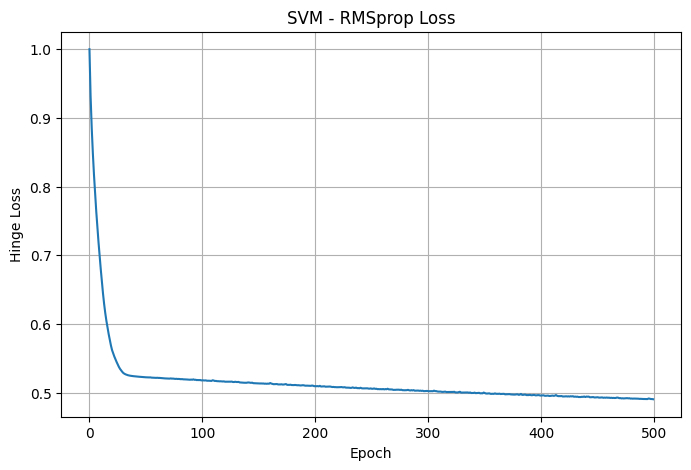

In [135]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("SVM - RMSprop Loss")

plt.xlabel("Epoch")

plt.ylabel("Hinge Loss")

plt.grid(True)

plt.show()

In [136]:
with torch.no_grad():

    test_scores = K_test @ W + b

    y_pred = torch.argmax(test_scores, dim=1)

    y_pred = y_pred.numpy()

    y_true = y_test.numpy()

In [137]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro"
)

recall = recall_score(
    y_true, y_pred, average="macro"
)

f1 = f1_score(
    y_true, y_pred, average="macro"
)

test_loss = hinge_loss(
    test_scores, y_test, W
).item()

print("SVM - RMSprop DESCENT Results")
print("--------------------------------")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("Loss     :", test_loss)

SVM - RMSprop DESCENT Results
--------------------------------
Accuracy : 0.8333333333333334
Precision: 0.8350168350168351
Recall   : 0.8333333333333334
F1 Score : 0.8329156223893066
Loss     : 0.5131914019584656


In [138]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=encoder.classes_
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.78      0.70      0.74        10
 Iris-virginica       0.73      0.80      0.76        10

       accuracy                           0.83        30
      macro avg       0.84      0.83      0.83        30
   weighted avg       0.84      0.83      0.83        30



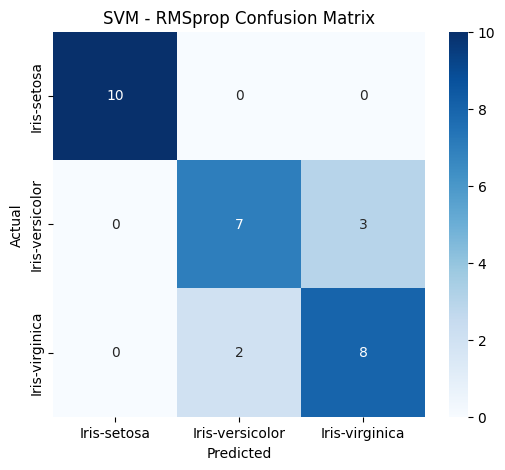

In [139]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("SVM - RMSprop Confusion Matrix")

plt.show()